### EXPERIMENT NO. 7
### MOTION ESTIMATION USING OPTICAL FLOW ALGORITHMS
### IN VIDEO SEQUENCES


### Name       : Akshit Negi
### CUID        : CU24250214
### Course     : B.Tech CSE
### Section    : CSE "B"
### Roll No.   : 04


### AIM


### To implement optical flow algorithms for estimating the motion
### of objects between consecutive video frames and analyze motion
### patterns for dynamic scene understanding using Python and OpenCV


 STEP 1: IMPORT REQUIRED LIBRARIES

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tkinter import Tk
from tkinter.filedialog import askopenfilename

 STEP 2: UPLOAD VIDEO FROM COMPUTER

In [3]:
from google.colab import files

print("Please upload a video file (e.g., .mp4, .avi, .mov).")
uploaded = files.upload()

if not uploaded:
    print("No file uploaded.")
    exit()

video_filename = next(iter(uploaded)) # Get the name of the first uploaded file
print(f"Video file '{video_filename}' uploaded successfully.")

Please upload a video file (e.g., .mp4, .avi, .mov).


Saving arlecchino-phantom-of-the-night.3840x2160.mp4 to arlecchino-phantom-of-the-night.3840x2160.mp4
Video file 'arlecchino-phantom-of-the-night.3840x2160.mp4' uploaded successfully.


STEP 3: READ TWO CONSECUTIVE VIDEO FRAMES

In [4]:
import cv2
import numpy as np # Added numpy import for robustness

video = cv2.VideoCapture(video_filename)

if not video.isOpened():
    print(f"Error: Could not open video file '{video_filename}'. Please ensure it's a valid video format and that the upload cell was executed correctly.")
    exit()

ret1, frame1 = video.read()
ret2, frame2 = video.read()

video.release()

if not ret1 or not ret2:
    print("Unable to read two consecutive frames from the video. The video might be too short, corrupted, or not a valid video file.")
    exit()

# Convert frames to grayscale

gray1 = cv2.cvtColor(
    frame1,
    cv2.COLOR_BGR2GRAY
)

gray2 = cv2.cvtColor(
    frame2,
    cv2.COLOR_BGR2GRAY
)

 STEP 4: DISPLAY CONSECUTIVE FRAMES

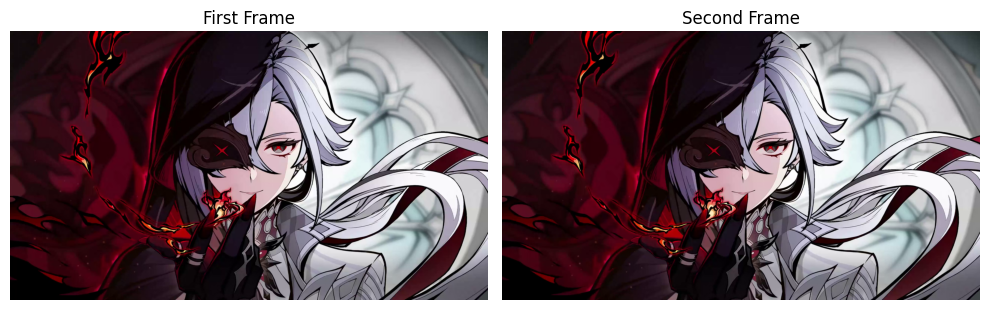

In [5]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(
    cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB)
)
plt.title("First Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB)
)
plt.title("Second Frame")
plt.axis("off")

plt.tight_layout()
plt.show()

 STEP 5: LUCAS-KANADE SPARSE OPTICAL FLOW

In [7]:
# Detect good feature points in the first frame

feature_params = dict(
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

points_old = cv2.goodFeaturesToTrack(
    gray1,
    mask=None,
    **feature_params
)

if points_old is None:
    print("No feature points detected.")
    exit()


# Lucas-Kanade parameters

lk_params = dict(
    winSize=(15, 15),
    maxLevel=2,
    criteria=(
        cv2.TERM_CRITERIA_EPS |
        cv2.TERM_CRITERIA_COUNT,
        10,
        0.03
    )
)


# Calculate optical flow

points_new, status, error = cv2.calcOpticalFlowPyrLK(
    gray1,
    gray2,
    points_old,
    None,
    **lk_params
)


# Select successfully tracked points

good_new = points_new[status == 1]
good_old = points_old[status == 1]


STEP 6: VISUALIZE LUCAS-KANADE MOTION VECTORS

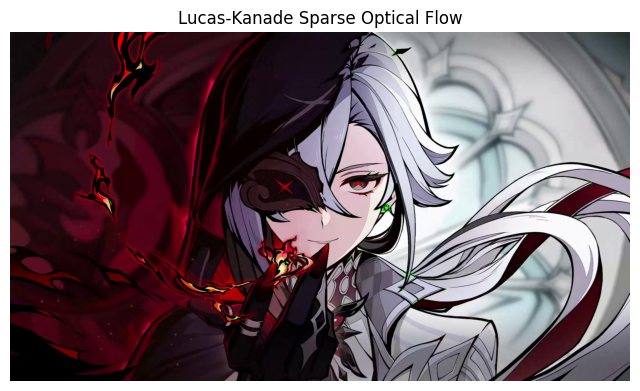

In [8]:
lucas_kanade = frame2.copy()

for new, old in zip(good_new, good_old):

    x_new, y_new = new.ravel()
    x_old, y_old = old.ravel()

    x_new = int(x_new)
    y_new = int(y_new)

    x_old = int(x_old)
    y_old = int(y_old)

    # Draw motion arrow

    cv2.arrowedLine(
        lucas_kanade,
        (x_old, y_old),
        (x_new, y_new),
        (255, 0, 0),
        2,
        tipLength=0.3
    )

    # Draw feature point

    cv2.circle(
        lucas_kanade,
        (x_new, y_new),
        4,
        (0, 255, 0),
        -1
    )


# Display Lucas-Kanade result

plt.figure(figsize=(8, 6))

plt.imshow(
    cv2.cvtColor(
        lucas_kanade,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Lucas-Kanade Sparse Optical Flow")
plt.axis("off")
plt.show()


STEP 7: FARNEBACK DENSE OPTICAL FLOW

In [9]:
# Calculate dense optical flow

flow = cv2.calcOpticalFlowFarneback(
    gray1,
    gray2,
    None,
    0.5,
    3,
    15,
    3,
    5,
    1.2,
    0
)

STEP 8: CALCULATE MOTION MAGNITUDE AND DIRECTION

In [10]:
magnitude, angle = cv2.cartToPolar(
    flow[..., 0],
    flow[..., 1]
)


STEP 9: CREATE COLOR-CODED FARNEBACK OPTICAL FLOW

In [11]:
hsv = np.zeros_like(frame1)

hsv[..., 1] = 255

# Direction of motion

hsv[..., 0] = (
    angle * 180 / np.pi / 2
)

# Magnitude of motion

hsv[..., 2] = cv2.normalize(
    magnitude,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)


# Convert HSV to BGR

farneback = cv2.cvtColor(
    hsv,
    cv2.COLOR_HSV2BGR
)

 STEP 10: DISPLAY FARNEBACK DENSE OPTICAL FLOW

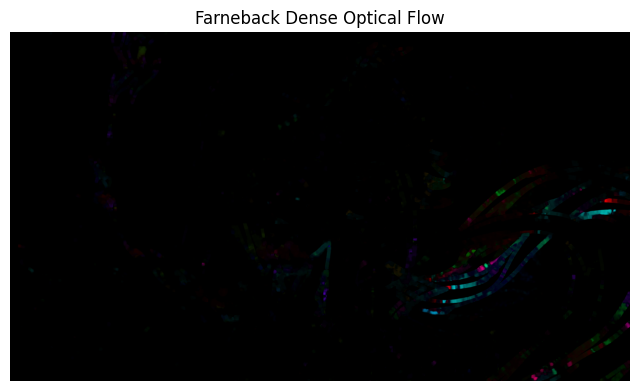

In [12]:
plt.figure(figsize=(8, 6))

plt.imshow(
    cv2.cvtColor(
        farneback,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Farneback Dense Optical Flow")
plt.axis("off")
plt.show()

STEP 11: COMPARISON OF OPTICAL FLOW METHODS

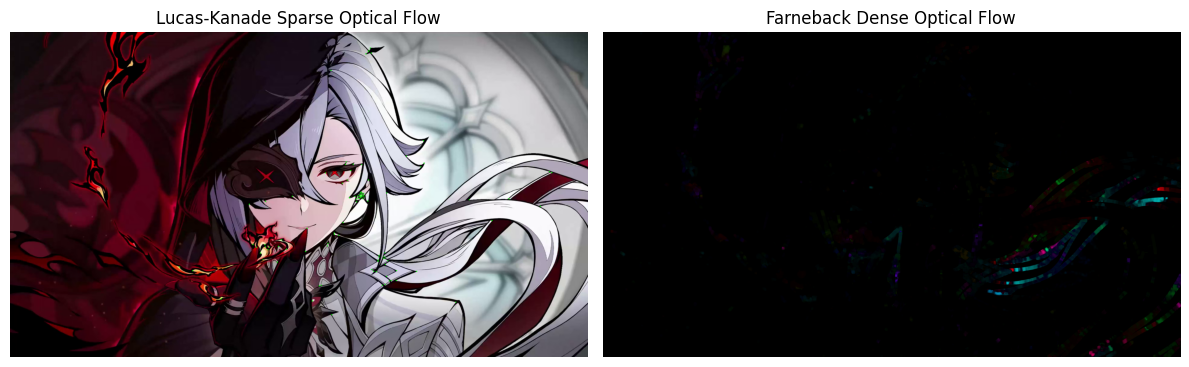

In [13]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)

plt.imshow(
    cv2.cvtColor(
        lucas_kanade,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Lucas-Kanade Sparse Optical Flow")
plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    cv2.cvtColor(
        farneback,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Farneback Dense Optical Flow")
plt.axis("off")

plt.tight_layout()
plt.show()


Q1. What is Optical Flow? Mention its applications.

Optical Flow is the apparent motion of pixels or objects between consecutive video frames.

Applications include:

Object tracking
Video surveillance
Autonomous navigation
Motion analysis
Human action recognition

Q2. Explain the basic principle of the Lucas-Kanade method.

Lucas-Kanade estimates the motion of selected feature points between two consecutive frames.

It assumes that the motion of pixels inside a small local window is approximately similar.

Q3. Differentiate between Dense and Sparse Optical Flow.

Sparse Optical Flow calculates motion only for selected feature points.

Dense Optical Flow calculates motion for almost every pixel.

Therefore, Sparse Optical Flow is generally faster, while Dense Optical Flow provides more complete motion information.

Q4. Compare Lucas-Kanade and Farneback Optical Flow.

Lucas-Kanade is a Sparse Optical Flow method that tracks selected feature points.

Farneback is a Dense Optical Flow method that estimates motion over the entire image.

Lucas-Kanade is generally simpler and faster, while Farneback provides more detailed motion information.

Q5. What assumptions are made in Optical Flow estimation?

The main assumptions are:

Brightness of a moving point remains approximately constant.
Motion between consecutive frames is relatively small.
Motion is locally smooth or consistent.

Q6. What factors affect the accuracy of Optical Flow?

The accuracy can be affected by:

Lighting changes
Camera movement
Object speed
Image noise
Motion blur
Occlusion
Texture of the object
Video frame rate

Q7. List five real-world applications of Optical Flow.

Autonomous driving
Video surveillance
Object tracking
Human action recognition
Motion detection and analysis

Q8. Why are grayscale images commonly used for Optical Flow?

Grayscale images contain intensity information that is sufficient for most optical flow calculations.

Using grayscale also reduces computational complexity because three color channels do not need to be processed separately.

Q9. What are the limitations of Optical Flow methods?

Limitations include:

Sensitivity to lighting changes
Difficulty with very large motion
Problems caused by occlusion
Motion blur can reduce accuracy
Camera motion can affect estimation
Textureless regions are difficult to track

Q10. How does Optical Flow contribute to autonomous driving, surveillance, and action recognition?

In autonomous driving, Optical Flow helps estimate the movement of vehicles, pedestrians and other objects.

In surveillance, it helps detect and track moving objects.

In action recognition, motion patterns can be used to identify activities and human movements.

Result

Thus, Lucas-Kanade Sparse Optical Flow and Farneback Dense Optical Flow were successfully implemented using Python and OpenCV.

Motion between consecutive video frames was estimated and visualized using motion vectors and color-coded optical flow.

The two methods were compared based on their motion estimation approach, computational complexity and applications.